# UCS420 Cognitive Computing - Assignment 8

## NLP II (Feature extraction, sentiment analysis and text generation)

Name: Vishu Verma

Roll number: 1024170242

In [1]:
import re
import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4", "vader_lexicon"]:
    nltk.download(pkg, quiet=True)

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

STOP = set(stopwords.words("english"))

## Question 1

My paragraph is about cricket.

In [2]:
paragraph = ("""Cricket is my favourite sport and I have been playing it since I was eight years old. """
             """Watching a Test match on a Sunday with my family is one of the best feelings, even when India is losing. """
             """I usually bat at number three for my college team, and I love playing the cover drive. """
             """The IPL has made the game faster, but I still think Test cricket is the real test of a player's patience. """
             """Virat Kohli's chase against Pakistan in the 2022 T20 World Cup is the best innings I have ever watched. """
             """Someday I want to watch a match live at Lord's in London.""")
print(paragraph)

Cricket is my favourite sport and I have been playing it since I was eight years old. Watching a Test match on a Sunday with my family is one of the best feelings, even when India is losing. I usually bat at number three for my college team, and I love playing the cover drive. The IPL has made the game faster, but I still think Test cricket is the real test of a player's patience. Virat Kohli's chase against Pakistan in the 2022 T20 World Cup is the best innings I have ever watched. Someday I want to watch a match live at Lord's in London.


**1. Lowercase and remove punctuation using re.**

In [3]:
lower = paragraph.lower()
clean = re.sub(r"[^\w\s]", "", lower)
print(clean)

cricket is my favourite sport and i have been playing it since i was eight years old watching a test match on a sunday with my family is one of the best feelings even when india is losing i usually bat at number three for my college team and i love playing the cover drive the ipl has made the game faster but i still think test cricket is the real test of a players patience virat kohlis chase against pakistan in the 2022 t20 world cup is the best innings i have ever watched someday i want to watch a match live at lords in london


**2. Tokenize into words and sentences.**

Sentences are taken from the original text because the full stops are needed to split them.

In [4]:
sentences = sent_tokenize(paragraph)
words = word_tokenize(clean)
print("Number of sentences:", len(sentences))
for i, s in enumerate(sentences, 1):
    print(i, s)
print("\nNumber of words:", len(words))
print(words)

Number of sentences: 6
1 Cricket is my favourite sport and I have been playing it since I was eight years old.
2 Watching a Test match on a Sunday with my family is one of the best feelings, even when India is losing.
3 I usually bat at number three for my college team, and I love playing the cover drive.
4 The IPL has made the game faster, but I still think Test cricket is the real test of a player's patience.
5 Virat Kohli's chase against Pakistan in the 2022 T20 World Cup is the best innings I have ever watched.
6 Someday I want to watch a match live at Lord's in London.

Number of words: 107
['cricket', 'is', 'my', 'favourite', 'sport', 'and', 'i', 'have', 'been', 'playing', 'it', 'since', 'i', 'was', 'eight', 'years', 'old', 'watching', 'a', 'test', 'match', 'on', 'a', 'sunday', 'with', 'my', 'family', 'is', 'one', 'of', 'the', 'best', 'feelings', 'even', 'when', 'india', 'is', 'losing', 'i', 'usually', 'bat', 'at', 'number', 'three', 'for', 'my', 'college', 'team', 'and', 'i', 'l

**3. split() vs word_tokenize()**

In [5]:
split_tokens = lower.split()
nltk_tokens = word_tokenize(lower)
print("split()        :", len(split_tokens), "tokens")
print(split_tokens[:25])
print("\nword_tokenize():", len(nltk_tokens), "tokens")
print(nltk_tokens[:25])

print("\nTokens that only split() gives:", sorted(set(split_tokens) - set(nltk_tokens)))
print("Tokens that only word_tokenize() gives:", sorted(set(nltk_tokens) - set(split_tokens)))

split()        : 107 tokens
['cricket', 'is', 'my', 'favourite', 'sport', 'and', 'i', 'have', 'been', 'playing', 'it', 'since', 'i', 'was', 'eight', 'years', 'old.', 'watching', 'a', 'test', 'match', 'on', 'a', 'sunday', 'with']

word_tokenize(): 119 tokens
['cricket', 'is', 'my', 'favourite', 'sport', 'and', 'i', 'have', 'been', 'playing', 'it', 'since', 'i', 'was', 'eight', 'years', 'old', '.', 'watching', 'a', 'test', 'match', 'on', 'a', 'sunday']

Tokens that only split() gives: ['drive.', 'faster,', 'feelings,', "kohli's", 'london.', "lord's", 'losing.', 'old.', 'patience.', "player's", 'team,', 'watched.']
Tokens that only word_tokenize() gives: ["'s", ',', '.', 'drive', 'faster', 'feelings', 'kohli', 'london', 'lord', 'losing', 'old', 'patience', 'player', 'team', 'watched']


`split()` only breaks on spaces, so punctuation stays attached to the word ("old.", "losing.", "player's").
`word_tokenize()` separates punctuation into its own tokens and splits the possessive "'s" off ("player", "'s"), so it gives more tokens.

**4. Remove stopwords.**

In [6]:
filtered = [w for w in words if w not in STOP]
print("Before:", len(words), " After:", len(filtered))
print(filtered)

Before: 107  After: 60
['cricket', 'favourite', 'sport', 'playing', 'since', 'eight', 'years', 'old', 'watching', 'test', 'match', 'sunday', 'family', 'one', 'best', 'feelings', 'even', 'india', 'losing', 'usually', 'bat', 'number', 'three', 'college', 'team', 'love', 'playing', 'cover', 'drive', 'ipl', 'made', 'game', 'faster', 'still', 'think', 'test', 'cricket', 'real', 'test', 'players', 'patience', 'virat', 'kohlis', 'chase', 'pakistan', '2022', 't20', 'world', 'cup', 'best', 'innings', 'ever', 'watched', 'someday', 'want', 'watch', 'match', 'live', 'lords', 'london']


**5. Word frequency distribution (without stopwords).**

[('test', 3), ('cricket', 2), ('playing', 2), ('match', 2), ('best', 2), ('favourite', 1), ('sport', 1), ('since', 1), ('eight', 1), ('years', 1)]


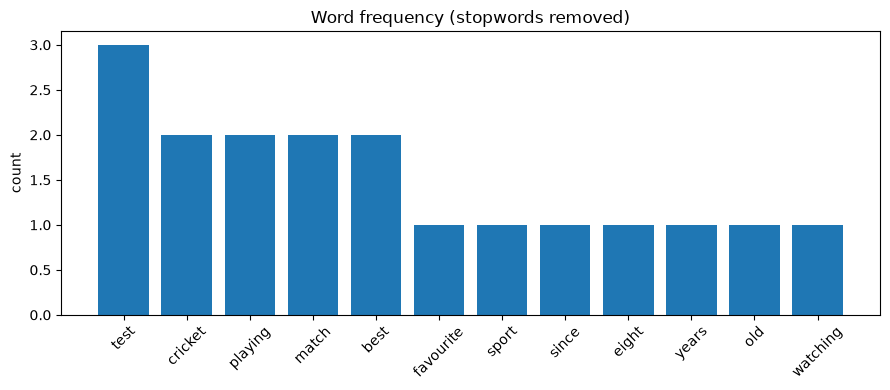

In [7]:
import matplotlib.pyplot as plt

fdist = FreqDist(filtered)
print(fdist.most_common(10))

top = fdist.most_common(12)
plt.figure(figsize=(9, 4))
plt.bar([w for w, _ in top], [c for _, c in top])
plt.xticks(rotation=45)
plt.title("Word frequency (stopwords removed)")
plt.ylabel("count")
plt.tight_layout()
plt.show()

## Question 2

Same paragraph as Q1.

**1. Words with only alphabets using re.findall()**

In [8]:
alpha_words = re.findall(r"\b[a-zA-Z]+\b", paragraph.lower())
print(len(alpha_words), alpha_words)

108 ['cricket', 'is', 'my', 'favourite', 'sport', 'and', 'i', 'have', 'been', 'playing', 'it', 'since', 'i', 'was', 'eight', 'years', 'old', 'watching', 'a', 'test', 'match', 'on', 'a', 'sunday', 'with', 'my', 'family', 'is', 'one', 'of', 'the', 'best', 'feelings', 'even', 'when', 'india', 'is', 'losing', 'i', 'usually', 'bat', 'at', 'number', 'three', 'for', 'my', 'college', 'team', 'and', 'i', 'love', 'playing', 'the', 'cover', 'drive', 'the', 'ipl', 'has', 'made', 'the', 'game', 'faster', 'but', 'i', 'still', 'think', 'test', 'cricket', 'is', 'the', 'real', 'test', 'of', 'a', 'player', 's', 'patience', 'virat', 'kohli', 's', 'chase', 'against', 'pakistan', 'in', 'the', 'world', 'cup', 'is', 'the', 'best', 'innings', 'i', 'have', 'ever', 'watched', 'someday', 'i', 'want', 'to', 'watch', 'a', 'match', 'live', 'at', 'lord', 's', 'in', 'london']


Numbers like 2022 are dropped. "player's" becomes "player" and "s" because the apostrophe is not a letter.

**2. Remove stopwords.**

In [9]:
alpha_filtered = [w for w in alpha_words if w not in STOP]
print(len(alpha_filtered), alpha_filtered)

58 ['cricket', 'favourite', 'sport', 'playing', 'since', 'eight', 'years', 'old', 'watching', 'test', 'match', 'sunday', 'family', 'one', 'best', 'feelings', 'even', 'india', 'losing', 'usually', 'bat', 'number', 'three', 'college', 'team', 'love', 'playing', 'cover', 'drive', 'ipl', 'made', 'game', 'faster', 'still', 'think', 'test', 'cricket', 'real', 'test', 'player', 'patience', 'virat', 'kohli', 'chase', 'pakistan', 'world', 'cup', 'best', 'innings', 'ever', 'watched', 'someday', 'want', 'watch', 'match', 'live', 'lord', 'london']


**3. Stemming with PorterStemmer**

In [10]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

ps = PorterStemmer()
stemmed = [ps.stem(w) for w in alpha_filtered]
print(stemmed)

['cricket', 'favourit', 'sport', 'play', 'sinc', 'eight', 'year', 'old', 'watch', 'test', 'match', 'sunday', 'famili', 'one', 'best', 'feel', 'even', 'india', 'lose', 'usual', 'bat', 'number', 'three', 'colleg', 'team', 'love', 'play', 'cover', 'drive', 'ipl', 'made', 'game', 'faster', 'still', 'think', 'test', 'cricket', 'real', 'test', 'player', 'patienc', 'virat', 'kohli', 'chase', 'pakistan', 'world', 'cup', 'best', 'inning', 'ever', 'watch', 'someday', 'want', 'watch', 'match', 'live', 'lord', 'london']


**4. Lemmatization with WordNetLemmatizer**

I lemmatize each word as a verb first and use the noun form if the verb form doesn't change it.

In [11]:
wnl = WordNetLemmatizer()

def lemma(w):
    v = wnl.lemmatize(w, pos="v")
    return v if v != w else wnl.lemmatize(w)

lemmatized = [lemma(w) for w in alpha_filtered]
print(lemmatized)

['cricket', 'favourite', 'sport', 'play', 'since', 'eight', 'year', 'old', 'watch', 'test', 'match', 'sunday', 'family', 'one', 'best', 'feeling', 'even', 'india', 'lose', 'usually', 'bat', 'number', 'three', 'college', 'team', 'love', 'play', 'cover', 'drive', 'ipl', 'make', 'game', 'faster', 'still', 'think', 'test', 'cricket', 'real', 'test', 'player', 'patience', 'virat', 'kohli', 'chase', 'pakistan', 'world', 'cup', 'best', 'inning', 'ever', 'watch', 'someday', 'want', 'watch', 'match', 'live', 'lord', 'london']


**5. Comparison**

In [12]:
import pandas as pd

cmp = pd.DataFrame({"word": alpha_filtered, "stem": stemmed, "lemma": lemmatized}).drop_duplicates()
print(cmp.to_string(index=False))
print("\nWords where stem and lemma differ:")
print(cmp[cmp.stem != cmp.lemma].to_string(index=False))

     word     stem     lemma
  cricket  cricket   cricket
favourite favourit favourite
    sport    sport     sport
  playing     play      play
    since     sinc     since
    eight    eight     eight
    years     year      year
      old      old       old
 watching    watch     watch
     test     test      test
    match    match     match
   sunday   sunday    sunday
   family   famili    family
      one      one       one
     best     best      best
 feelings     feel   feeling
     even     even      even
    india    india     india
   losing     lose      lose
  usually    usual   usually
      bat      bat       bat
   number   number    number
    three    three     three
  college   colleg   college
     team     team      team
     love     love      love
    cover    cover     cover
    drive    drive     drive
      ipl      ipl       ipl
     made     made      make
     game     game      game
   faster   faster    faster
    still    still     still
    think    t

- The stemmer just chops endings, so it gives non-words like "favourit", "famili", "patienc", "realli".
- The lemmatizer always returns a real dictionary word ("playing" -> "play", "watched" -> "watch", "feelings" -> "feeling").
- Stemming is faster and is fine for search engines or bag of words models where we only need words with the same root to match.
- Lemmatization is better when the output has to be read by a person or the meaning matters, like chatbots or question answering.

## Question 3

Three short product reviews of my own.

In [13]:
texts = [
    "The phone battery lasts two full days and the camera is amazing in low light.",
    "Delivery was late and the laptop screen arrived cracked, very poor packaging.",
    "Great headphones, the noise cancellation is amazing but the battery drains fast.",
]
for i, t in enumerate(texts, 1):
    print(f"Text {i}: {t}")

Text 1: The phone battery lasts two full days and the camera is amazing in low light.
Text 2: Delivery was late and the laptop screen arrived cracked, very poor packaging.
Text 3: Great headphones, the noise cancellation is amazing but the battery drains fast.


**1. Bag of Words using CountVectorizer**

In [14]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

cv = CountVectorizer(stop_words="english")
bow = cv.fit_transform(texts)
bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(), index=["Text 1", "Text 2", "Text 3"])
print("Vocabulary size:", len(cv.vocabulary_))
bow_df

Vocabulary size: 22


,amazing,arrived,battery,camera,cancellation,cracked,days,delivery,drains,fast,...,laptop,lasts,late,light,low,noise,packaging,phone,poor,screen
Text 1,1,0,1,1,0,0,1,0,0,0,...,0,1,0,1,1,0,0,1,0,0
Text 2,0,1,0,0,0,1,0,1,0,0,...,1,0,1,0,0,0,1,0,1,1
Text 3,1,0,1,0,1,0,0,0,1,1,...,0,0,0,0,0,1,0,0,0,0


**2. TF-IDF using TfidfVectorizer**

In [15]:
tfidf = TfidfVectorizer(stop_words="english")
tf = tfidf.fit_transform(texts)
tf_df = pd.DataFrame(tf.toarray(), columns=tfidf.get_feature_names_out(), index=["Text 1", "Text 2", "Text 3"])
tf_df.round(3)

,amazing,arrived,battery,camera,cancellation,cracked,days,delivery,drains,fast,...,laptop,lasts,late,light,low,noise,packaging,phone,poor,screen
Text 1,0.284,0.000,0.284,0.374,0.000,0.000,0.374,0.000,0.000,0.000,...,0.000,0.374,0.000,0.374,0.374,0.000,0.000,0.374,0.000,0.000
Text 2,0.000,0.354,0.000,0.000,0.000,0.354,0.000,0.354,0.000,0.000,...,0.354,0.000,0.354,0.000,0.000,0.000,0.354,0.000,0.354,0.354
Text 3,0.284,0.000,0.284,0.000,0.374,0.000,0.000,0.000,0.374,0.374,...,0.000,0.000,0.000,0.000,0.000,0.374,0.000,0.000,0.000,0.000


**3. Top 3 keywords per text**

In [16]:
for name, row in tf_df.iterrows():
    top3 = row.sort_values(ascending=False).head(3)
    print(name, "->", ", ".join(f"{w} ({s:.3f})" for w, s in top3.items()))

Text 1 -> lasts (0.374), camera (0.374), phone (0.374)
Text 2 -> screen (0.354), poor (0.354), packaging (0.354)
Text 3 -> headphones (0.374), drains (0.374), noise (0.374)


- Words that appear in only one text (like "camera", "cracked", "headphones") get a higher idf, so they come out on top. These words actually tell us what each review is about.
- "amazing" and "battery" are in two texts, so their score is lower even though they appear in each of them.
- Inside one text every word appears only once, so all the unique words tie on score and the top 3 shown is just the first three of the tie. Text 2 shares no words with the others, so all of its words tie.

## Question 4

Two short texts on AI and Blockchain.

In [17]:
ai_text = """Artificial intelligence lets computers learn patterns from large amounts of data.
Machine learning models are trained on examples and then make predictions on new data.
AI is used in voice assistants, recommendation systems and self driving cars.
Deep learning uses neural networks with many layers to understand images and text.
The quality of an AI system depends a lot on the data it is trained on."""

bc_text = """Blockchain is a distributed ledger that stores data in blocks linked together.
Every block holds a hash of the previous block, so old records cannot be changed easily.
The network of computers agrees on new blocks using a consensus method like proof of work.
Bitcoin and Ethereum are the most popular systems built on blockchain.
It removes the need for a central authority to trust the data."""

**1. Preprocess and tokenize**

In [18]:
def preprocess(text):
    text = re.sub(r"[^a-z\s]", " ", text.lower())
    return [lemma(w) for w in word_tokenize(text) if w not in STOP and len(w) > 1]

ai_tokens = preprocess(ai_text)
bc_tokens = preprocess(bc_text)
print("AI tokens        :", ai_tokens)
print("\nBlockchain tokens:", bc_tokens)

AI tokens        : ['artificial', 'intelligence', 'let', 'computer', 'learn', 'pattern', 'large', 'amount', 'data', 'machine', 'learn', 'model', 'train', 'example', 'make', 'prediction', 'new', 'data', 'ai', 'use', 'voice', 'assistant', 'recommendation', 'system', 'self', 'drive', 'car', 'deep', 'learn', 'use', 'neural', 'network', 'many', 'layer', 'understand', 'image', 'text', 'quality', 'ai', 'system', 'depend', 'lot', 'data', 'train']

Blockchain tokens: ['blockchain', 'distribute', 'ledger', 'store', 'data', 'block', 'link', 'together', 'every', 'block', 'hold', 'hash', 'previous', 'block', 'old', 'record', 'change', 'easily', 'network', 'computer', 'agree', 'new', 'block', 'use', 'consensus', 'method', 'like', 'proof', 'work', 'bitcoin', 'ethereum', 'popular', 'system', 'build', 'blockchain', 'remove', 'need', 'central', 'authority', 'trust', 'data']


**2a. Jaccard similarity using sets**

In [19]:
A, B = set(ai_tokens), set(bc_tokens)
common = A & B
jaccard = len(common) / len(A | B)
print("Common words:", common)
print(f"|A ∩ B| = {len(common)}, |A ∪ B| = {len(A | B)}")
print(f"Jaccard similarity = {jaccard:.4f}")

Common words: {'new', 'data', 'network', 'computer', 'system', 'use'}
|A ∩ B| = 6, |A ∪ B| = 66
Jaccard similarity = 0.0909


**2b. Cosine similarity using TfidfVectorizer**

In [20]:
from sklearn.metrics.pairwise import cosine_similarity

vec = TfidfVectorizer()
m = vec.fit_transform([" ".join(ai_tokens), " ".join(bc_tokens)])
cos = cosine_similarity(m[0], m[1])[0][0]
print(f"Cosine similarity = {cos:.4f}")

Cosine similarity = 0.1234


**2c. Which one is better here**

Both values are low, which makes sense since the topics are different. The only overlap is general words like "data", "computer", "system", "network", "use" and "new".

Jaccard only checks if a word is present or not, so a word used once counts the same as "data" which is used 4 times in the AI text. Cosine with TF-IDF uses the weights, so the repeated shared word "data" pushes the score up a bit, and words that are unique to one text don't affect the angle much.

For my texts cosine similarity is more useful because it takes word frequency into account and doesn't depend on how long the texts are. Jaccard is simpler and fine for very short texts or keyword sets.

## Question 5

Short reviews for a food delivery app. I used both TextBlob and VADER.

In [21]:
from textblob import TextBlob
from nltk.sentiment import SentimentIntensityAnalyzer

reviews = [
    "The food arrived hot and fresh, the delivery guy was polite and super quick. Loved it!",
    "Absolutely amazing biryani, best I have ordered online. Great app and great offers.",
    "The order came 50 minutes late and the pizza was cold. Really disappointed.",
    "Customer support never replied and I was charged twice. Terrible experience.",
    "I ordered a sandwich through the app at 8 pm and it came in a paper bag.",
    "Nice packaging and tasty desserts, I will definitely order again.",
]

sia = SentimentIntensityAnalyzer()
rows = []
for r in reviews:
    tb = TextBlob(r).sentiment
    rows.append({"review": r, "polarity": round(tb.polarity, 3), "subjectivity": round(tb.subjectivity, 3),
                 "vader_compound": sia.polarity_scores(r)["compound"]})
sent = pd.DataFrame(rows)

**2. Classify as Positive / Negative / Neutral**

Using the VADER compound score with the usual ±0.05 cutoff.

In [22]:
def label(c):
    if c >= 0.05:
        return "Positive"
    if c <= -0.05:
        return "Negative"
    return "Neutral"

sent["sentiment"] = sent.vader_compound.apply(label)
pd.set_option("display.max_colwidth", 90)
sent

,review,polarity,subjectivity,vader_compound,sentiment
0,"The food arrived hot and fresh, the delivery guy was polite and super quick. Loved it!",0.418,0.663,0.8858,Positive
1,"Absolutely amazing biryani, best I have ordered online. Great app and great offers.",0.660,0.540,0.9569,Positive
2,The order came 50 minutes late and the pizza was cold. Really disappointed.,-0.550,0.783,-0.5256,Negative
3,Customer support never replied and I was charged twice. Terrible experience.,-1.000,1.000,-0.2960,Negative
4,I ordered a sandwich through the app at 8 pm and it came in a paper bag.,0.000,0.000,0.0000,Neutral
5,"Nice packaging and tasty desserts, I will definitely order again.",0.300,0.750,0.6705,Positive


In [23]:
print(sent.sentiment.value_counts())

sentiment
Positive    3
Negative    2
Neutral     1
Name: count, dtype: int64


**3. Word cloud of the positive reviews**

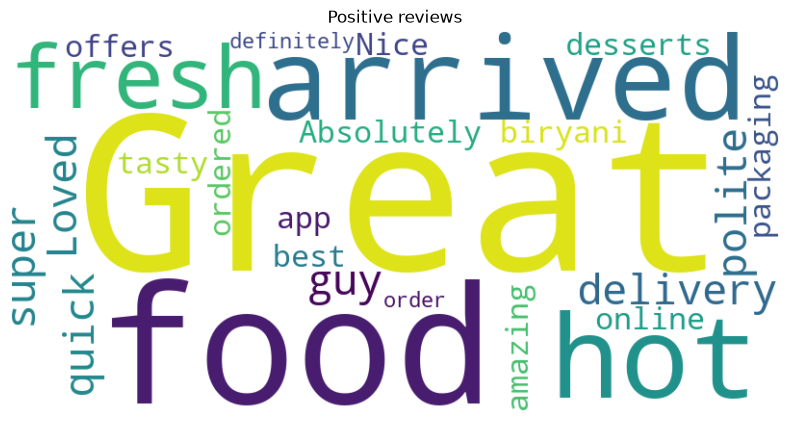

In [24]:
from wordcloud import WordCloud

pos_text = " ".join(sent[sent.sentiment == "Positive"].review)
wc = WordCloud(width=800, height=400, background_color="white", stopwords=STOP).generate(pos_text)
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Positive reviews")
plt.show()

## Question 6

Training paragraph (about 100 words) on space exploration.

In [25]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

np.random.seed(42)
tf.random.set_seed(42)

train_text = """space exploration helps us understand our universe and our place in it.
the moon was the first place humans visited outside the earth.
rockets carry satellites and astronauts into space.
satellites help us with weather forecasts, maps and communication.
the mars rover sends pictures of red rocks and dust back to earth.
scientists study the stars to learn how the universe began.
one day humans will build a base on the moon and then travel to mars.
space exploration is expensive but it teaches us a lot about our own planet.
young students dream of becoming astronauts and exploring the stars."""
print(len(train_text.split()), "words")

101 words


**1. Tokenize using Tokenizer()**

In [26]:
tok = Tokenizer()
tok.fit_on_texts([train_text])
vocab_size = len(tok.word_index) + 1
print("Vocabulary size:", vocab_size)
print(list(tok.word_index.items())[:15])

Vocabulary size: 69
[('the', 1), ('and', 2), ('space', 3), ('us', 4), ('our', 5), ('to', 6), ('exploration', 7), ('universe', 8), ('place', 9), ('it', 10), ('moon', 11), ('humans', 12), ('earth', 13), ('satellites', 14), ('astronauts', 15)]


**2. Input sequences (n-gram style) and the LSTM model**

In [27]:
seqs = []
for line in train_text.split("\n"):
    ids = tok.texts_to_sequences([line])[0]
    for i in range(1, len(ids)):
        seqs.append(ids[:i + 1])

max_len = max(len(s) for s in seqs)
seqs = pad_sequences(seqs, maxlen=max_len, padding="pre")
X, y = seqs[:, :-1], seqs[:, -1]
print("Number of sequences:", len(seqs), " max length:", max_len)
print("Example:", X[5], "->", y[5])

model = Sequential([
    Embedding(vocab_size, 50),
    LSTM(150),
    Dense(vocab_size, activation="softmax"),
])
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, max_len - 1))
model.summary()

Number of sequences: 92  max length: 15
Example: [ 0  0  0  0  0  0  0  0  3  7 20  4 21  5] -> 8


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 14, 50)         │         3,450 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 150)            │       120,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 69)             │        10,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,469 (525.27 KB)

 Trainable params: 134,469 (525.27 KB)

 Non-trainable params: 0 (0.00 B)

**3. Train and generate text**

Final loss: 0.0408  accuracy: 0.9783


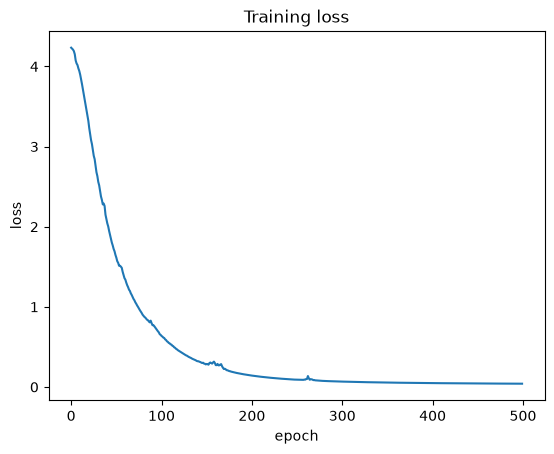

In [28]:
history = model.fit(X, y, epochs=500, verbose=0)
print(f"Final loss: {history.history['loss'][-1]:.4f}  accuracy: {history.history['accuracy'][-1]:.4f}")

plt.plot(history.history["loss"])
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Training loss")
plt.show()

In [29]:
index_word = {i: w for w, i in tok.word_index.items()}

def generate(seed, n_words=10):
    text = seed
    for _ in range(n_words):
        ids = tok.texts_to_sequences([text])[0]
        ids = pad_sequences([ids], maxlen=max_len - 1, padding="pre")
        nxt = int(np.argmax(model.predict(ids, verbose=0)))
        text += " " + index_word.get(nxt, "")
    return text

for seed in ["space", "the moon", "rockets"]:
    print(generate(seed))

space exploration is expensive but it teaches us a lot about
the moon was the first place humans visited outside the earth earth


rockets carry satellites and astronauts into space space communication communication communication


The model has only seen about 100 words, so it mostly reproduces phrases from the paragraph that start with the seed. When it reaches the end of a line it has seen, it starts repeating words because it never learned what comes after that.